<a href="https://colab.research.google.com/github/MPEC150024/DS-ML/blob/main/DS_ML_Covid_19_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd


student_dict = {
    'Name': ['Amit Kumar', 'Neha Sharma', 'Rahul Verma', 'Priya Singh'],
    'Course': ['B.Tech', 'BCA', 'B.Sc', 'MCA'],
    'Class': ['Year 2', 'Year 3', 'Year 1', 'Year 2']
}


df = pd.DataFrame(student_dict)


print(df)


          Name  Course   Class
0   Amit Kumar  B.Tech  Year 2
1  Neha Sharma     BCA  Year 3
2  Rahul Verma    B.Sc  Year 1
3  Priya Singh     MCA  Year 2


In [2]:
data = pd.DataFrame(student_dict )
data


,Name,Course,Class
0,Amit Kumar,B.Tech,Year 2
1,Neha Sharma,BCA,Year 3
2,Rahul Verma,B.Sc,Year 1
3,Priya Singh,MCA,Year 2


In [39]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sudalairajkumar/covid19-in-india")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'covid19-in-india' dataset.
Path to dataset files: /kaggle/input/covid19-in-india


In [40]:
import os

print(os.listdir(path))

['StatewiseTestingDetails.csv', 'covid_vaccine_statewise.csv', 'covid_19_india.csv']


In [41]:
import pandas as pd
file_path = os.path.join(path, "covid_19_india.csv")
df = pd.read_csv(file_path)

In [42]:
df.head()

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1
1,2,2020-01-31,6:00 PM,Kerala,1,0,0,0,1
2,3,2020-02-01,6:00 PM,Kerala,2,0,0,0,2
3,4,2020-02-02,6:00 PM,Kerala,3,0,0,0,3
4,5,2020-02-03,6:00 PM,Kerala,3,0,0,0,3


In [43]:
#understand the dataset
print("shape",df.shape)
print("columns",df.columns)
print("Data types",df.dtypes)

shape (18110, 9)
columns Index(['Sno', 'Date', 'Time', 'State/UnionTerritory',
       'ConfirmedIndianNational', 'ConfirmedForeignNational', 'Cured',
       'Deaths', 'Confirmed'],
      dtype='object')
Data types Sno                          int64
Date                        object
Time                        object
State/UnionTerritory        object
ConfirmedIndianNational     object
ConfirmedForeignNational    object
Cured                        int64
Deaths                       int64
Confirmed                    int64
dtype: object


In [44]:
df.isnull().sum()

,0
Sno,0
Date,0
Time,0
State/UnionTerritory,0
ConfirmedIndianNational,0
ConfirmedForeignNational,0
Cured,0
Deaths,0
Confirmed,0


In [45]:
df.duplicated().sum()

np.int64(0)

In [46]:
df.drop_duplicates()

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1
1,2,2020-01-31,6:00 PM,Kerala,1,0,0,0,1
2,3,2020-02-01,6:00 PM,Kerala,2,0,0,0,2
3,4,2020-02-02,6:00 PM,Kerala,3,0,0,0,3
4,5,2020-02-03,6:00 PM,Kerala,3,0,0,0,3
...,...,...,...,...,...,...,...,...,...
18105,18106,2021-08-11,8:00 AM,Telangana,-,-,638410,3831,650353
18106,18107,2021-08-11,8:00 AM,Tripura,-,-,77811,773,80660
18107,18108,2021-08-11,8:00 AM,Uttarakhand,-,-,334650,7368,342462
18108,18109,2021-08-11,8:00 AM,Uttar Pradesh,-,-,1685492,22775,1708812


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Sno                       18110 non-null  int64 
 1   Date                      18110 non-null  object
 2   Time                      18110 non-null  object
 3   State/UnionTerritory      18110 non-null  object
 4   ConfirmedIndianNational   18110 non-null  object
 5   ConfirmedForeignNational  18110 non-null  object
 6   Cured                     18110 non-null  int64 
 7   Deaths                    18110 non-null  int64 
 8   Confirmed                 18110 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.2+ MB


In [48]:
df["Date"] = pd.to_datetime(df["Date"])

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18110 entries, 0 to 18109
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Sno                       18110 non-null  int64         
 1   Date                      18110 non-null  datetime64[ns]
 2   Time                      18110 non-null  object        
 3   State/UnionTerritory      18110 non-null  object        
 4   ConfirmedIndianNational   18110 non-null  object        
 5   ConfirmedForeignNational  18110 non-null  object        
 6   Cured                     18110 non-null  int64         
 7   Deaths                    18110 non-null  int64         
 8   Confirmed                 18110 non-null  int64         
dtypes: datetime64[ns](1), int64(4), object(4)
memory usage: 1.2+ MB


In [50]:
df["Recovered"] = df["Cured"]

In [51]:
# create a new column
df["Active"] = df["Confirmed"] - df["Cured"] - df["Deaths"]

In [52]:
df.sample(10)

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed,Recovered,Active
5683,5684,2020-08-28,8:00 AM,Uttarakhand,-,-,11775,228,17277,11775,5274
15058,15059,2021-05-19,8:00 AM,Delhi,-,-,1329899,22111,1402873,1329899,50863
13294,13295,2021-03-31,8:00 AM,Delhi,-,-,642166,11016,660611,642166,7429
11510,11511,2021-02-09,8:00 AM,Nagaland,-,-,11988,88,12160,11988,84
7789,7790,2020-10-28,8:00 AM,Assam,-,-,191030,914,204789,191030,12845
15289,15290,2021-05-25,8:00 AM,Mizoram,-,-,8019,34,10622,8019,2569
17687,17688,2021-07-31,8:00 AM,Goa,-,-,166813,3146,171052,166813,1093
5229,5230,2020-08-15,8:00 AM,Uttar Pradesh,-,-,92526,2335,145287,92526,50426
3487,3488,2020-06-27,8:00 AM,Sikkim,-,-,39,0,86,39,47
15903,15904,2021-06-11,8:00 AM,Odisha,-,-,772972,3167,837226,772972,61087


In [53]:
#check
df.tail(3)

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed,Recovered,Active
18107,18108,2021-08-11,8:00 AM,Uttarakhand,-,-,334650,7368,342462,334650,444
18108,18109,2021-08-11,8:00 AM,Uttar Pradesh,-,-,1685492,22775,1708812,1685492,545
18109,18110,2021-08-11,8:00 AM,West Bengal,-,-,1506532,18252,1534999,1506532,10215


In [54]:
df.isnull().sum()

,0
Sno,0
Date,0
Time,0
State/UnionTerritory,0
ConfirmedIndianNational,0
ConfirmedForeignNational,0
Cured,0
Deaths,0
Confirmed,0
Recovered,0


In [55]:
df.head(1000)

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed,Recovered,Active
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1,0,1
1,2,2020-01-31,6:00 PM,Kerala,1,0,0,0,1,0,1
2,3,2020-02-01,6:00 PM,Kerala,2,0,0,0,2,0,2
3,4,2020-02-02,6:00 PM,Kerala,3,0,0,0,3,0,3
4,5,2020-02-03,6:00 PM,Kerala,3,0,0,0,3,0,3
...,...,...,...,...,...,...,...,...,...,...,...
995,996,2020-04-16,5:00 PM,Assam,-,-,5,1,33,5,27
996,997,2020-04-16,5:00 PM,Bihar,-,-,29,1,74,29,44
997,998,2020-04-16,5:00 PM,Chandigarh,-,-,7,0,21,7,14
998,999,2020-04-16,5:00 PM,Chhattisgarh,-,-,17,0,33,17,16


In [56]:
#check
df.sample(100)

,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed,Recovered,Active
14959,14960,2021-05-16,8:00 AM,Ladakh,-,-,14619,165,16333,14619,1549
1087,1088,2020-04-18,5:00 PM,Tripura,-,-,1,0,2,1,1
1420,1421,2020-04-29,5:00 PM,Chhattisgarh,-,-,34,0,38,34,4
14398,14399,2021-04-30,8:00 AM,Tripura,-,-,33612,396,35169,33612,1161
17428,17429,2021-07-24,8:00 AM,Arunachal Pradesh,-,-,40619,212,45188,40619,4357
...,...,...,...,...,...,...,...,...,...,...,...
6323,6324,2020-09-16,8:00 AM,Dadra and Nagar Haveli and Daman and Diu,-,-,2552,2,2783,2552,229
14919,14920,2021-05-15,8:00 AM,Jammu and Kashmir,-,-,181762,3027,236790,181762,52001
11299,11300,2021-02-03,8:00 AM,Sikkim,-,-,5876,135,6096,5876,85
6140,6141,2020-09-10,8:00 AM,West Bengal,-,-,162992,3730,190063,162992,23341


In [63]:
state_data.head()

,State/UnionTerritory,Confirmed,Deaths,Recovered,Active
0,Andaman and Nicobar Islands,7548,129,7412,1154
1,Andhra Pradesh,1985182,13564,1952736,211554
2,Arunachal Pradesh,50605,248,47821,4465
3,Assam,576149,5420,559684,56295
4,Bihar,725279,9646,715352,115152


In [71]:
import numpy as np
# now calculate recovery rate

state_data["Recovery Rate"] = state_data["Recovered"] / state_data["Confirmed"].replace(0,pd.NA)*100

In [73]:
# Death rate
state_data["Death Rate"] = state_data["Deaths"] / state_data["Confirmed"].replace(0,pd.NA)*100

In [74]:
state_data.head()

,State/UnionTerritory,Confirmed,Deaths,Recovered,Active,Recovery Rate,Deaths Rate,Death Rate
0,Andaman and Nicobar Islands,7548,129,7412,1154,98.198198,1.709062,1.709062
1,Andhra Pradesh,1985182,13564,1952736,211554,98.365591,0.683262,0.683262
2,Arunachal Pradesh,50605,248,47821,4465,94.498567,0.490070,0.490070
3,Assam,576149,5420,559684,56295,97.142232,0.940729,0.940729
4,Bihar,725279,9646,715352,115152,98.631285,1.329971,1.329971


In [75]:
state_data["Recovery Rate"] = state_data["Recovery Rate"].round(2)
state_data["Death Rate"] = state_data["Death Rate"].round(2)

In [ ]:
state_data.head()

,State/UnionTerritory,Confirmed,Deaths,Recovered,Active,Recovery Rate,Death Rate
0,Andaman and Nicobar Islands,7548,129,7412,1154,98.20,1.71
1,Andhra Pradesh,1985182,13564,1952736,211554,98.37,0.68
2,Arunachal Pradesh,50605,248,47821,4465,94.50,0.49
3,Assam,576149,5420,559684,56295,97.14,0.94
4,Bihar,725279,9646,715352,115152,98.63,1.33


/tmp/ipykernel_1672/4072616000.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1672/4072616000.py:5: UserWarning: 
The palette list has fewer values (3) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


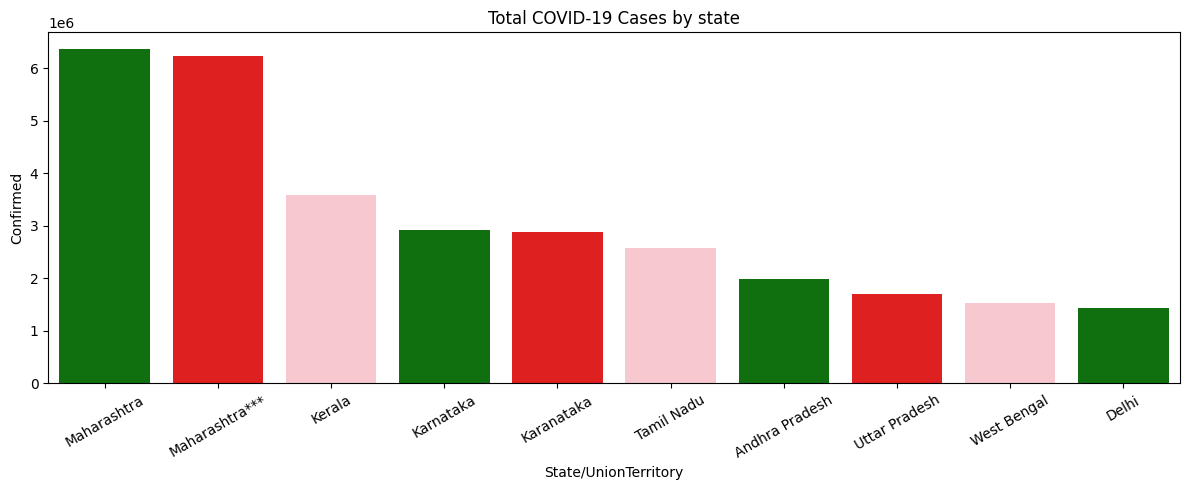

In [80]:
# Total Cases by State
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,5,))
sns.barplot(
    data = state_data.sort_values("Confirmed",ascending=False).head(10),
    x = "State/UnionTerritory",
    y = "Confirmed",
    palette=["green","red","pink"]
)
plt.title("Total COVID-19 Cases by state")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [62]:
#create  our state_level summary
state_data=(
    df.groupby("State/UnionTerritory")
    [["Confirmed", "Deaths", "Recovered","Active"]]
    .max()
    .reset_index()
)

In [68]:
state_data["Recovery Rate"]=state_data["Recovered"]/state_data["Confirmed"].replace(0,pd.NA)*100

In [69]:
state_data["Deaths Rate"]=state_data["Deaths"]/state_data["Confirmed"].replace(0,pd.NA)*100

/tmp/ipykernel_1672/3601599632.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1672/3601599632.py:4: UserWarning: 
The palette list has fewer values (3) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


<Axes: xlabel='State/UnionTerritory', ylabel='Recovery Rate'>

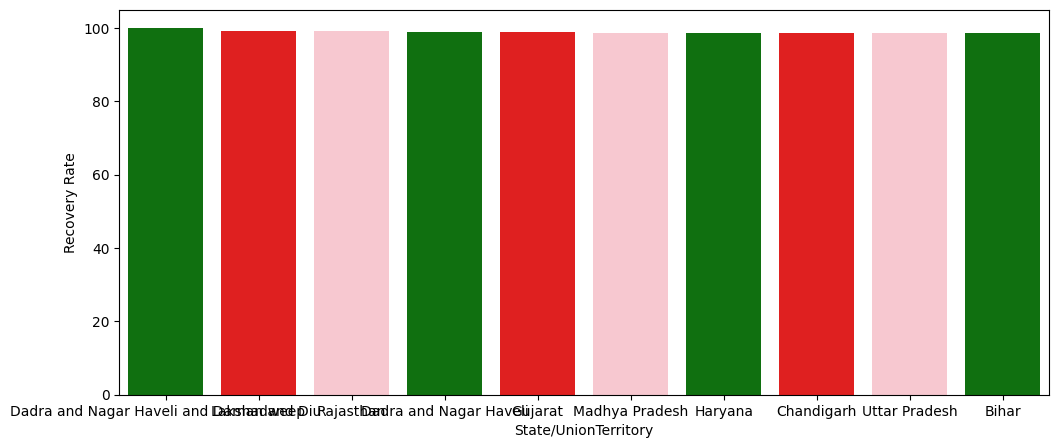

In [100]:
# Recovery Rate vs Death Rate
rate_data=state_data.sort_values("Recovery Rate",ascending=False).head(10)
plt.figure(figsize=(12,5,))
sns.barplot(
    data = rate_data,
    x = "State/UnionTerritory",
    y = "Recovery Rate",
    palette=["green","red","pink"]

    )


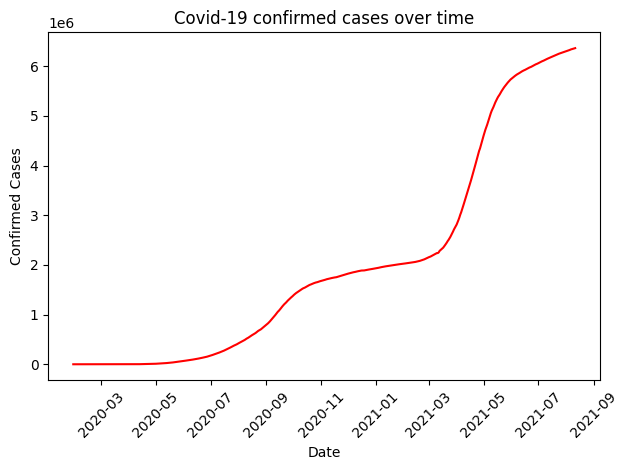

In [97]:
daily_cases = (
    df.groupby("Date")
     ["Confirmed"]
    .max()
    .reset_index()
)
sns.lineplot(
    data = daily_cases,
    x = "Date",
    y = "Confirmed",
    color = "red"
)
plt.title("Covid-19 confirmed cases over time")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()